# **First Assignment - Business Process Prediction Simulation, and Optimization - Winter Semester 2026/2027**

### Milena Fernanda Rivera Hernández

### Option 2: Advanced Data Science Analysis (Clustering)

### **Execution note:**
---

Sections 3.1 to 3.3 are run locally in a virtual environment pinned in `requirements.lock.txt` (except for the petri and BPMN visualizations). However, this advanced DS analysis was run separately in Google Colab due to its availability of GPUs.

The clustering workflow is the most computationally demanding part: it builds a feature matrix for all 31,509 cases and trains K-means repeatedly for every candidate number of clusters and feature set, including extra runs to measure stability. Keeping it in a separate notebook also leaves the process-mining pipeline of the main notebook `assignmentI.ipynb` untouched :)

In addition, to keep my work reproducible, the notebook installs the required packages, fixes every random seed (`random_state = 22`), and reads the same dataset file and event filter (`lifecycle:transition == "complete"`) as the main notebook.

NOTE: It is possible for Library versions in Colab to differ from the local lock file, so results can differ slightly from a local run. But honestly, for main purpose of the assignment, those slight differences may not held relevance.

## **Analyisis**

### **1. Hypothesis**

The main idea is based on our course goal of simulating a process.

---

**Research question.**

Do the BPIC-17 cases form behaviourally distinct groups (clusters of process variants) that differ in structure, duration and resource involvement?

---

**Hypothesis.**

The cases can be split into a small number of stable groups (for example, cases that follow the main flow directly and cases with rework or long waiting times) that differ clearly in the number of events, the case duration and the number of resources involved.

---

**Brief comment on why it matters for simulation.**

A business process simulation model that treats all cases as one population averages very different behaviours which results in lack of generalization in real word set ups.

If distinct and stable groups exist, each group can be given its own simulation parameters (i.e. share of arrivals, duration distributions, resource usage), which could make the simulated process more realistic.

---

**Hypothesis Evaluation.**

- *Internal quality:* silhouette (primary) and Davies-Bouldin (secondary) on unseen validation and test cases.
- *Stability:* Adjusted Rand Index (ARI) between solutions obtained with different random seeds.
- *External validation:* agreement (ARI, NMI, pairwise F1) with case labels that are **not** used as features (application type, loan goal, requested amount).

In [1]:
!pip install pm4py

In [2]:
# Libraries

# To create output folder
import os

import numpy as np

# Tried using pandas with GPU but had problems with the reindex function
import pandas as pd

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Read log
import pm4py

# Data Science
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from cuml.cluster import KMeans # to use GPUs
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score,
                            davies_bouldin_score,
                            calinski_harabasz_score,
                            adjusted_rand_score,
                            normalized_mutual_info_score,
                            v_measure_score)
from sklearn.metrics.cluster import pair_confusion_matrix

# General configuartion

# seed for splits, K-means, sampling and PCA
random_state = 22
np.random.seed(random_state)

# output folder
out = "../generated_files"
os.makedirs(out, exist_ok=True)

min_transition_support = 0.01 # keep transitions present in >= 1 % of training cases
stability_extra_seeds = 5 # extra K-means runs used to measure stability
stability_min = 0.80 # minimum mean ARI to accept a configuration
min_cluster_share = 0.05 # every cluster must hold >= 5 % of the validation cases



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [3]:
# Auxiliar functions for the whole notebook

def create_case_features(event_log, activity_vocab, transition_vocab):
    """
    Builds one row of features per case:
      - presence of each activity
      - relative frequency of each activity transition
      - process complexity
      - performance and resource involvement.
    It relies on the global variables case, act, timestamp and resource.
    -------
    Params:
        - event_log (pandas.DataFrame): The event log (one row per event).
        - activity_vocab (list): The activities that become presence features.
        - transition_vocab (list): The (activity, next activity) pairs that
          become features.
    -------
    Return:
        - pandas.DataFrame: One row per case (indexed by case id) with all features.
    """
    act_idx = {a: i for i, a in enumerate(activity_vocab)}
    trn_idx = {t: i for i, t in enumerate(transition_vocab)}

    event_log = event_log.sort_values([case_, timestamp], kind="stable")
    t0 = event_log[timestamp].min()
    event_log = event_log.assign(_hours=(event_log[timestamp] - t0).dt.total_seconds() / 3600)
    has_resource = resource in event_log.columns

    case_ids, act_rows, trn_rows, num_rows = [], [], [], []

    for case_id, group in event_log.groupby(case_, sort=False):

        sequence = group[act].tolist()
        hours = group["_hours"].to_numpy()

        # Activity presence
        act_vec = np.zeros(len(activity_vocab))
        for a in set(sequence):
            if a in act_idx:
                act_vec[act_idx[a]] = 1

        # Relative frequency of transitions
        pairs = list(zip(sequence[:-1], sequence[1:]))
        total = max(len(pairs), 1)
        trn_vec = np.zeros(len(transition_vocab))
        for p in pairs:
            j = trn_idx.get(p)
            if j is not None:
                trn_vec[j] += 1 / total

        # Complexity and performance
        diffs = np.diff(hours)
        numeric = {"n_events": len(group),
                   "n_unique_activities": len(set(sequence)),
                   "duration_hours": float(hours.max() - hours.min()),
                   "mean_inter_event_hours": float(diffs.mean()) if len(diffs) else 0.0,
                   "median_inter_event_hours": float(np.median(diffs)) if len(diffs) else 0.0,
                   "max_inter_event_hours": float(diffs.max()) if len(diffs) else 0.0}

        # Resource involvement
        if has_resource:
            res_seq = group[resource].dropna().tolist()
            numeric["n_resources"] = len(set(res_seq))
            numeric["n_handovers"] = sum(p != c for p, c in zip(res_seq[:-1], res_seq[1:]))
        else:
            numeric["n_resources"] = 0
            numeric["n_handovers"] = 0

        case_ids.append(case_id)
        act_rows.append(act_vec)
        trn_rows.append(trn_vec)
        num_rows.append(numeric)

    index = pd.Index(case_ids, name=case_)
    act_df = pd.DataFrame(act_rows, index=index, columns=[f"act|{a}" for a in activity_vocab])
    trn_df = pd.DataFrame(trn_rows, index=index,
                          columns=[f"trn|{a} -> {b}" for a, b in transition_vocab])
    num_df = pd.DataFrame(num_rows, index=index)
    return pd.concat([act_df, trn_df, num_df], axis=1).fillna(0)


def log_transform(X, columns):
    """
    Applies log(1 + x) to the given columns to reduce the influence of very
    long tails.
    -------
    Params:
        - X (pandas.DataFrame): The feature matrix.
        - columns (list): The names of the columns to transform.
    -------
    Return:
        - pandas.DataFrame: A copy of X with the selected columns transformed.
    """
    X = X.copy()
    X[columns] = np.log1p(X[columns])
    return X


def pairwise_f1(labels_true, labels_pred):
    """
    Calculates the pairwise F1 score between a clustering and a reference
    labelling. A pair of cases counts as positive when both cases are in the
    same cluster (predicted) or in the same eference class (true).
    The score is invariant to the numbering of the clusters.
    -------
    Params:
        - labels_true (array-like): The reference class of each case.
        - labels_pred (array-like): The cluster assigned to each case.
    -------
    Return:
        - tuple: The F1 score, the pairwise precision and the pairwise recall (floats).
    """
    c = pair_confusion_matrix(labels_true, labels_pred)
    tp, fp, fn = c[1, 1], c[0, 1], c[1, 0]
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
    return float(f1), float(precision), float(recall)


def evaluate_external(labels_true, labels_pred):
    """
    Evaluates the agreement between a clustering and a reference labelling that
    was not used as a feature. The pairwise F1 is not chance-corrected, so it
    is reported together with ARI.
    -------
    Params:
        - labels_true (array-like): The reference class of each case.
        - labels_pred (array-like): The cluster assigned to each case.
    -------
    Return:
        - dict: ARI, NMI, V-measure, pairwise precision, pairwise recall and pairwise F1.
    """
    f1, precision, recall = pairwise_f1(labels_true, labels_pred)
    return {"ARI": adjusted_rand_score(labels_true, labels_pred),
            "NMI": normalized_mutual_info_score(labels_true, labels_pred),
            "V-measure": v_measure_score(labels_true, labels_pred),
            "pairwise_precision": precision,
            "pairwise_recall": recall,
            "pairwise_F1": f1}


def clustering_stability(X_fit, X_eval, k, ref_labels, seeds):
    """
    Measures how stable a K-means solution is across random initialisations.
    It trains models with different seeds and compares their assignments on
    X_eval with the reference assignments using the Adjusted Rand Index.
    -------
    Params:
        - X_fit (numpy.ndarray): The scaled training features used to fit the
          models.
        - X_eval (numpy.ndarray): The scaled features on which the assignments
          are compared.
        - k (int): The number of clusters.
        - ref_labels (numpy.ndarray): The reference assignments of X_eval.
        - seeds (iterable): The random seeds of the models compared with the
          reference.
    -------
    Return:
        - tuple: The mean and the standard deviation of the ARI (floats;
          closer to 1 = more stable).
    """
    aris = []
    for s in seeds:
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10,
                        random_state=s).fit(X_fit).predict(X_eval)
        aris.append(adjusted_rand_score(ref_labels, labels))
    return float(np.mean(aris)), float(np.std(aris))

In [4]:
# Event Log
df = pm4py.read_xes("BPI Challenge 2017.xes.gz")
display(df.head(3))

/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


parsing log, completed traces ::   0%|          | 0/31509 [00:00<?, ?it/s]

,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))

print("\nLifecycle transitions:")
display(df["lifecycle:transition"].value_counts().to_frame("Events"))

Columns:
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']

Data types:
Action                           object
org:resource                     object
concept:name                     object
EventOrigin                      object
EventID                          object
lifecycle:transition             object
time:timestamp           datetime64[ns]
case:LoanGoal                    object
case:ApplicationType             object
case:concept:name                object
case:RequestedAmount            float64
FirstWithdrawalAmount           float64
NumberOfTerms                   float64
Accepted                         object
MonthlyCost                     float64
Selected                         object
CreditScore      

,Missing values
FirstWithdrawalAmount,1159272
NumberOfTerms,1159272
Accepted,1159272
MonthlyCost,1159272
Selected,1159272
CreditScore,1159272
OfferedAmount,1159272
OfferID,1051413
Action,0
org:resource,0



Lifecycle transitions:


,Events
lifecycle:transition,
complete,475306
suspend,215402
schedule,149104
start,128227
resume,127160
ate_abort,85224
withdraw,21844


In [6]:
# Event log variables, same as main notebook :) except case_ because I remembered
# it is a reserved word in python.

case_ = "case:concept:name"
act = "concept:name"
timestamp = "time:timestamp"
resource = "org:resource"
lifec = "lifecycle:transition"

In [7]:
# Data pre-processing

df2 = df.copy()

# Event filter as log_c in the main notebook
df2 = df2[df2[lifec] == "complete"].copy()
# Same sort
df2 = df2.sort_values([case_, timestamp], kind="stable").reset_index(drop=True)

print("Events:", len(df2))
print("Cases:", df2[case_].nunique())
print("Activities:", df2[act].nunique())
print("Resources:", df2[resource].nunique())

Events: 475306
Cases: 31509
Activities: 24
Resources: 144


In [8]:
# Some additional stats

print("Observation period:", df2[timestamp].min(), "to", df2[timestamp].max())

events_per_case = df2.groupby(case_).size()
display(events_per_case.describe().to_frame("Events per case").round(2))

Observation period: 2016-01-01 09:51:15.304000 to 2017-02-01 14:00:30.347000


,Events per case
count,31509.00
mean,15.08
std,4.60
min,7.00
25%,12.00
50%,14.00
75%,17.00
max,54.00


,Case duration (hours)
count,31509.00
mean,524.31
std,310.52
min,0.06
25%,271.26
50%,457.42
75%,755.74
max,4057.74


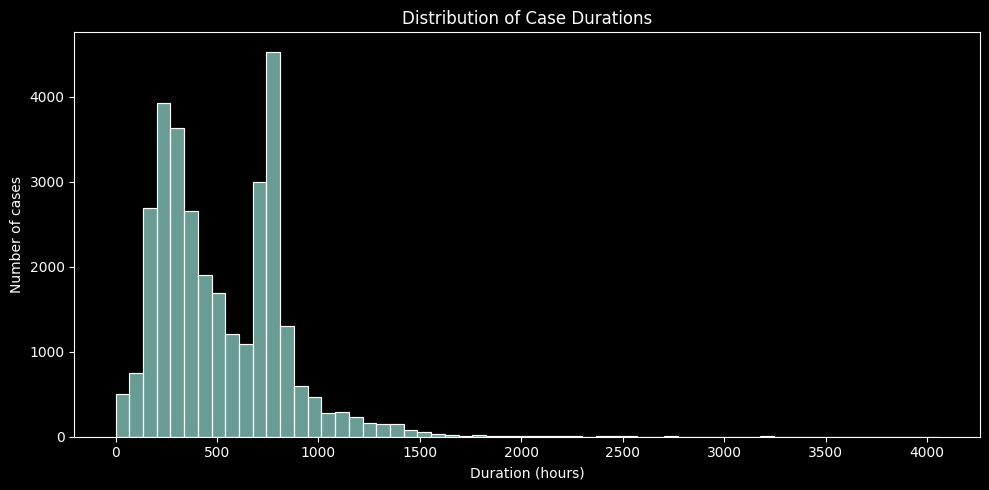

In [9]:
# Taking duration in hours
case_durations = df2.groupby(case_)[timestamp].agg(["min", "max"])
case_durations["duration_hours"] = (case_durations["max"] - case_durations["min"]).dt.total_seconds() / 3600

display(case_durations["duration_hours"].describe().to_frame("Case duration (hours)").round(2))

plt.style.use('dark_background')
plt.figure(figsize=(10, 5))
sns.histplot(case_durations["duration_hours"], bins=60)
plt.title("Distribution of Case Durations")
plt.xlabel("Duration (hours)")
plt.ylabel("Number of cases")
plt.tight_layout()
plt.show()

In [10]:
# Split of cases ids (60 / 20 / 20, by case)

# Unique id's
case_ids = df2[case_].drop_duplicates().to_numpy()

# 80 % for model development, 20 % final test
train_val_ids, test_ids = train_test_split(case_ids,
                                           test_size=0.20,
                                           random_state=random_state)

# Remaining 80 % will be 60 % training and 20 % validation overall
train_ids, val_ids = train_test_split(train_val_ids,
                                      test_size=0.25,
                                      random_state=random_state)

train_log = df2[df2[case_].isin(train_ids)].copy()
val_log = df2[df2[case_].isin(val_ids)].copy()
test_log = df2[df2[case_].isin(test_ids)].copy()

for name, ids in [("Training", train_ids), ("Validation", val_ids), ("Test", test_ids)]:
    print(f"{name}: {len(ids)} cases ({len(ids) / len(case_ids):.1%})")

Training: 18905 cases (60.0%)
Validation: 6302 cases (20.0%)
Test: 6302 cases (20.0%)


In [11]:
# Training Feature Vocabulary
activity_vocab = sorted(train_log[act].dropna().unique())

# Number of training cases that contain each transition
transition_cases = {}
for _, group in train_log.groupby(case_, sort=False):
    sequence = group[act].tolist()
    for t in set(zip(sequence[:-1], sequence[1:])):
        transition_cases[t] = transition_cases.get(t, 0) + 1

n_train_cases = len(train_ids)
all_transitions = len(transition_cases)

# Keep only transitions with enough support (rare ones would get a huge weight after scaling)
transition_vocab = sorted(
    t for t, n in transition_cases.items()
    if n / n_train_cases >= min_transition_support)

print("Activity features:", len(activity_vocab))
print(f"Transitions observed in training: {all_transitions}")
print(f"Transitions kept (support >= {min_transition_support:.0%}): {len(transition_vocab)}")

Activity features: 24
Transitions observed in training: 153
Transitions kept (support >= 1%): 57


In [12]:
# Training, validation and test features

X_train = create_case_features(train_log, activity_vocab, transition_vocab)
X_val = create_case_features(val_log, activity_vocab, transition_vocab)
X_test = create_case_features(test_log, activity_vocab, transition_vocab)

# Identical feature columns in the three matrices
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

display(X_train.iloc[:, -9:].head())

Training matrix: (18905, 89)
Validation matrix: (6302, 89)
Test matrix: (6302, 89)


,trn|W_Validate application -> O_Cancelled,n_events,n_unique_activities,duration_hours,mean_inter_event_hours,median_inter_event_hours,max_inter_event_hours,n_resources,n_handovers
case:concept:name,,,,,,,,,
Application_1000086665,0.0,10,10,782.054210,86.894912,0.018490,735.987062,2,2
Application_1000334415,0.0,16,15,327.104617,21.806974,0.006616,167.513939,5,4
Application_100034150,0.0,17,16,267.300101,16.706256,0.015752,139.756594,6,6
Application_1000386745,0.0,16,14,263.457755,17.563850,0.024816,142.743303,7,6
Application_1000474975,0.0,13,13,307.492685,25.624390,0.017838,187.491179,3,2


In [13]:
# Feature check

for name, matrix in [("Training", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"\n{name} dataset")
    print("Number of cases:", len(matrix))

# Features that are constant in training must be removed
# We must select the feature columns that actually vary in the training set
# and drop the rest
non_constant_columns = X_train.columns[X_train.nunique() > 1]

X_train = X_train[non_constant_columns]
X_val = X_val[non_constant_columns]
X_test = X_test[non_constant_columns]

print("\nFeatures after removing constant columns:", X_train.shape[1])


Training dataset
Number of cases: 18905

Validation dataset
Number of cases: 6302

Test dataset
Number of cases: 6302

Features after removing constant columns: 84


In [14]:
# The application of log transform, feature sets, and standarization is
# explained in the report

numeric_columns = ["n_events", "n_unique_activities", "duration_hours",
                   "mean_inter_event_hours","median_inter_event_hours",
                   "max_inter_event_hours", "n_resources", "n_handovers"]

# We select the features that are not constant so log_transform won't raise
# a KeyError on it
skewed_cols = [c for c in numeric_columns if c != "n_unique_activities" and c in X_train.columns]

# Raw matrices (X_train, X_val, X_test) are kept for interpretation
# transformed ones for modelling
Xt_train = log_transform(X_train, skewed_cols)
Xt_val = log_transform(X_val, skewed_cols)
Xt_test = log_transform(X_test, skewed_cols)

act_cols = [c for c in X_train.columns if c.startswith("act|")]
trn_cols = [c for c in X_train.columns if c.startswith("trn|")]
num_cols = [c for c in numeric_columns if c in X_train.columns]

feature_sets = {"full": act_cols + trn_cols + num_cols,
                "compact": act_cols + num_cols}

scaled = {}
for name, cols in feature_sets.items():
    scaler = StandardScaler().fit(Xt_train[cols]) # fitted on training only
    scaled[name] = {"train": scaler.transform(Xt_train[cols]),
                    "val": scaler.transform(Xt_val[cols]),
                    "test": scaler.transform(Xt_test[cols])}
    print(f"{name}: {len(cols)} features")
    print(f"        Training matrix {scaled[name]['train'].shape}")

full: 84 features
        Training matrix (18905, 84)
compact: 27 features
        Training matrix (18905, 27)


### **2. Approach and Result**

I decided to implement a **Grid search.** so K-means is trained on the training cases for each feature set and each number of clusters `k` (2 to 10). Every configuration is evaluated on the **validation** cases with the silhouette, the Davies-Bouldin index and the Calinski-Harabasz index, plus the stability across random seeds and the size of the smallest cluster.

In [15]:
# K-means GRID SEARCH

k_values = list(range(2, 11))
stability_seeds = [random_state + i + 1 for i in range(stability_extra_seeds)]
results = []

for set_name in feature_sets:

    S = scaled[set_name]

    for k in k_values:

        print(f"Evaluating feature set '{set_name}', k = {k}")

        model = KMeans(n_clusters=k,
                       init="k-means++",
                       n_init=10,
                       max_iter=300,
                       random_state=random_state)
        model.fit(S["train"])
        val_labels = model.predict(S["val"])
        n_val_clusters = len(np.unique(val_labels))
        silhouette = davies_bouldin = calinski_harabasz = np.nan

        if 2 <= n_val_clusters < len(val_labels):
            silhouette = silhouette_score(S["val"],
                                          val_labels,
                                          sample_size=min(5000, len(val_labels)),
                                          random_state=random_state)
            davies_bouldin = davies_bouldin_score(S["val"],
                                                  val_labels)
            calinski_harabasz = calinski_harabasz_score(S["val"],
                                                        val_labels)
        stab_mean, stab_std = clustering_stability(S["train"],
                                                   S["val"],
                                                   k,
                                                   val_labels,
                                                   stability_seeds)

        results.append({"feature_set": set_name,
                       "n_clusters": k,
                       "inertia_train": model.inertia_,
                       "silhouette_val": silhouette,
                       "davies_bouldin_val": davies_bouldin,
                       "calinski_harabasz_val": calinski_harabasz,
                       "stability_ari": stab_mean,
                       "stability_std": stab_std,
                       "min_cluster_share": np.bincount(val_labels, minlength=k).min() / len(val_labels),
                       "n_clusters_validation": n_val_clusters})

results_df = pd.DataFrame(results)
results_df.to_csv(f"{out}/clustering_grid_results.csv", index=False)

display(results_df.round(4))

Evaluating feature set 'full', k = 2
Evaluating feature set 'full', k = 3
Evaluating feature set 'full', k = 4
Evaluating feature set 'full', k = 5
Evaluating feature set 'full', k = 6
Evaluating feature set 'full', k = 7
Evaluating feature set 'full', k = 8
Evaluating feature set 'full', k = 9
Evaluating feature set 'full', k = 10
Evaluating feature set 'compact', k = 2
Evaluating feature set 'compact', k = 3
Evaluating feature set 'compact', k = 4
Evaluating feature set 'compact', k = 5
Evaluating feature set 'compact', k = 6
Evaluating feature set 'compact', k = 7
Evaluating feature set 'compact', k = 8
Evaluating feature set 'compact', k = 9
Evaluating feature set 'compact', k = 10


,feature_set,n_clusters,inertia_train,silhouette_val,davies_bouldin_val,calinski_harabasz_val,stability_ari,stability_std,min_cluster_share,n_clusters_validation
0,full,2,1.320209e+06,0.2082,1.7565,1320.6966,1.0000,0.0000,0.3123,2
1,full,3,1.213696e+06,0.2360,1.9220,1014.7848,1.0000,0.0000,0.1230,3
2,full,4,1.140920e+06,0.2219,2.2854,846.6851,0.9413,0.1174,0.1228,4
3,full,5,1.088236e+06,0.1489,2.2369,743.9893,0.7881,0.0976,0.1219,5
4,full,6,1.046606e+06,0.1783,2.1663,676.1313,0.7801,0.0871,0.0143,6
5,full,7,1.010378e+06,0.1731,2.0850,619.9608,0.7193,0.1152,0.0143,7
6,full,8,9.762233e+05,0.1861,2.0166,590.6858,0.8423,0.0664,0.0059,8
7,full,9,9.454360e+05,0.1939,1.9972,535.3500,0.8128,0.0802,0.0282,9
8,full,10,9.191145e+05,0.1810,1.9418,521.3011,0.6795,0.0954,0.0235,10
9,compact,2,3.649507e+05,0.3560,1.1531,2571.2444,1.0000,0.0000,0.3123,2


In [16]:
# Final config for model

valid_results = results_df.dropna(subset=["silhouette_val", "davies_bouldin_val", "calinski_harabasz_val"]).copy()

# Eligible: stable across seeds and without tiny clusters
valid_results["eligible"] = ((valid_results["stability_ari"] >= stability_min) & (valid_results["min_cluster_share"] >= min_cluster_share))

ranked_results = valid_results.sort_values(by=["eligible", "silhouette_val", "davies_bouldin_val"],
                                           ascending=[False, False, True])

display(ranked_results[["feature_set", "n_clusters", "silhouette_val",
                        "davies_bouldin_val","calinski_harabasz_val",
                        "stability_ari", "min_cluster_share", "eligible"]].head(15).round(4))

# Case that no config meets the criteria
if not valid_results["eligible"].any():
    print("WARNING: no configuration met criteria: the best silhouette is used instead.")

best_row = ranked_results.iloc[0]
best_set = best_row["feature_set"]
best_k = int(best_row["n_clusters"])
print(f"\nBest config! = '{best_set}', k = {best_k}")

,feature_set,n_clusters,silhouette_val,davies_bouldin_val,calinski_harabasz_val,stability_ari,min_cluster_share,eligible
10,compact,3,0.3823,1.2533,2056.9821,1.0000,0.1231,True
9,compact,2,0.3560,1.1531,2571.2444,1.0000,0.3123,True
1,full,3,0.2360,1.9220,1014.7848,1.0000,0.1230,True
2,full,4,0.2219,2.2854,846.6851,0.9413,0.1228,True
0,full,2,0.2082,1.7565,1320.6966,1.0000,0.3123,True
11,compact,4,0.3914,1.3199,1778.6954,0.9866,0.0175,False
13,compact,6,0.3139,1.4174,1563.8417,0.8900,0.0059,False
12,compact,5,0.3095,1.6131,1636.7581,0.9838,0.0175,False
14,compact,7,0.3025,1.3571,1470.7732,0.8551,0.0059,False
17,compact,10,0.2993,1.3290,1271.9834,0.7362,0.0051,False



Best config! = 'compact', k = 3


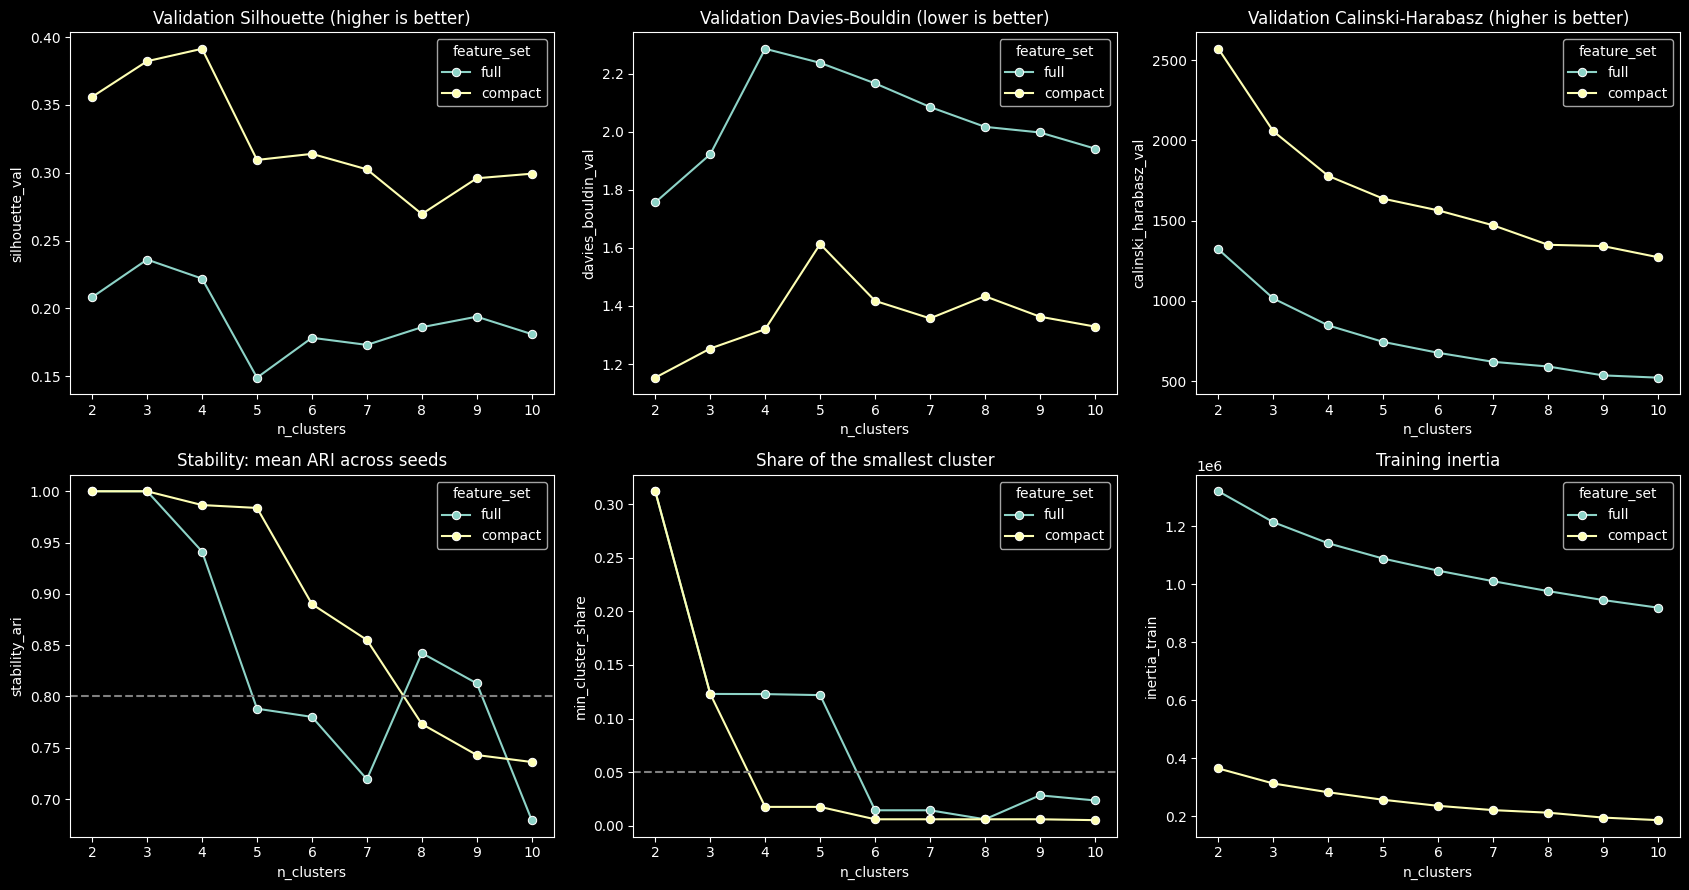

In [17]:
# Grid Search Results

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

panels = [("silhouette_val", "Validation Silhouette (higher is better)"),
          ("davies_bouldin_val", "Validation Davies-Bouldin (lower is better)"),
          ("calinski_harabasz_val", "Validation Calinski-Harabasz (higher is better)"),
          ("stability_ari", "Stability: mean ARI across seeds"),
          ("min_cluster_share", "Share of the smallest cluster"),
          ("inertia_train", "Training inertia")]

for ax, (metric, title) in zip(axes.ravel(), panels):
    sns.lineplot(data=valid_results,
                 x="n_clusters",
                 y=metric,
                 hue="feature_set",
                 marker="o",
                 ax=ax)
    ax.set_title(title)

axes[1, 0].axhline(stability_min, ls="--", color="grey")
axes[1, 1].axhline(min_cluster_share, ls="--", color="grey")

plt.tight_layout()
plt.savefig(f"{out}/clustering_grid_search.pdf", bbox_inches="tight")
plt.show()

In [18]:
# Now, we can fit the selected K-means model

S = scaled[best_set]

best_model = KMeans(n_clusters=best_k,
                    init="k-means++",
                    n_init=10,
                    max_iter=300,
                    random_state=random_state)
best_model.fit(S["train"])

train_clusters = best_model.predict(S["train"])
val_clusters = best_model.predict(S["val"])
test_clusters = best_model.predict(S["test"])

In [19]:
# Final test evaluation
plt.style.use('dark_background')
test_silhouette = silhouette_score(S["test"],
                                   test_clusters,
                                   sample_size=min(5000, len(test_clusters)),
                                   random_state=random_state)

test_davies_bouldin = davies_bouldin_score(S["test"], test_clusters)
test_calinski_harabasz = calinski_harabasz_score(S["test"], test_clusters)
test_stab_mean, test_stab_std = clustering_stability(S["train"],
                                                     S["test"],
                                                     best_k,
                                                     test_clusters,
                                                     stability_seeds)

print("FINAL TEST RESULTS")
print("-*-"*10)
print("* Silhouette:", round(test_silhouette, 4))
print("* Davies-Bouldin:", round(test_davies_bouldin, 4))
print("* Calinski-Harabasz:", round(test_calinski_harabasz, 4))
print(f"* Stability (ARI across seeds): {test_stab_mean:.3f} +/- {test_stab_std:.3f}")
print("* Training inertia:", round(best_model.inertia_, 2))

FINAL TEST RESULTS
-*--*--*--*--*--*--*--*--*--*-
* Silhouette: 0.374
* Davies-Bouldin: 1.2673
* Calinski-Harabasz: 1965.4825
* Stability (ARI across seeds): 1.000 +/- 0.000
* Training inertia: 313217.87


,Number of cases,Percentage
Cluster,,
0,3650,57.92
1,1894,30.05
2,758,12.03


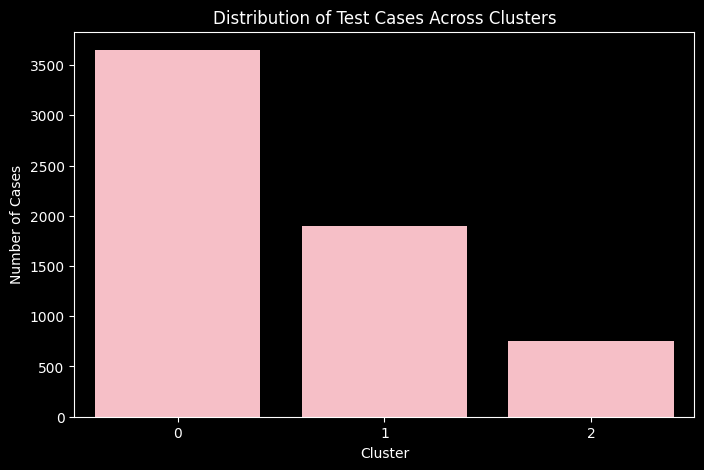

In [20]:
# Visualization of cluster distribution for test

cluster_distribution = pd.Series(test_clusters, name="Cluster").value_counts().sort_index()
cluster_summary = pd.DataFrame({ "Number of cases": cluster_distribution,
                                 "Percentage": (cluster_distribution / len(test_clusters) * 100).round(2)})
display(cluster_summary)

plt.style.use('dark_background')
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_summary.index,
            y=cluster_summary["Number of cases"],
            color = 'lightpink')
plt.title("Distribution of Test Cases Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Cases")
plt.savefig(f"{out}/cluster_distribution.pdf", bbox_inches="tight")
plt.show()

In [21]:
# I must add, that an external validation for labels that are not features must be done
# because the model never sees them

first = df2.groupby(case_).first().loc[X_test.index]

ref = pd.DataFrame(index=X_test.index)

print(ref.isna().sum())
print(len(ref), "test cases")


rows = {}
for c in ref.columns:
    mask = ref[c].notna().to_numpy()
    rows[c] = evaluate_external(ref.loc[mask, c], test_clusters[mask])
    rows[c]["n_cases_used"] = int(mask.sum())

external = pd.DataFrame(rows).T
display(external.round(3))

Series([], dtype: float64)
6302 test cases


""


**Explanation:**

High values mean the clusters mostly reproduce that label; values near 0 (ARI) mean no relation. A low score doesn’t mean the clustering failed: your clusters describe process behaviour, and a label like loan goal doesn’t have to determine behaviour.

In [22]:
# Numerical cluster comparison with unscaled features

cluster_analysis = X_test.copy()
cluster_analysis["cluster"] = test_clusters

numeric_features = [c for c in numeric_columns if c in cluster_analysis.columns]

display(cluster_analysis.groupby("cluster")[numeric_features].agg(["mean", "median"]).round(2))

sim_summary = cluster_analysis.groupby("cluster").agg(n_cases=("n_events", "size"),
                                                      median_events=("n_events", "median"),
                                                      median_duration_days=("duration_hours", lambda s: s.median() / 24),
                                                      median_resources=("n_resources", "median"),
                                                      median_handovers=("n_handovers", "median"))
sim_summary["share_of_cases_%"] = sim_summary["n_cases"] / sim_summary["n_cases"].sum() * 100
display(sim_summary.round(2))
sim_summary.round(3).to_csv(f"{out}/cluster_simulation_summary.csv")

n_events        n_unique_activities        duration_hours          \
            mean median                mean median           mean  median   
cluster                                                                     
0          16.90   16.0               13.99   14.0         455.63  364.06   
1          11.69   11.0               10.48   10.0         711.07  759.55   
2          15.59   15.0               13.59   14.0         400.90  334.93   

        mean_inter_event_hours        median_inter_event_hours         \
                          mean median                     mean median   
cluster                                                                 
0                        28.59  24.75                     0.02   0.01   
1                        68.36  77.25                     0.00   0.00   
2                        27.63  24.40                     0.02   0.00   

        max_inter_event_hours         n_resources        n_handovers         
                         mean  median        mean median        mean median  
cluster                                                                      
0                      256.93  195.53        5.28    5.0        4.78    5.0  
1                      639.98  736.30        2.43    2.0        2.04    2.0  
2                      243.17  192.18        4.73    4.0        3.94    4.0

,n_cases,median_events,median_duration_days,median_resources,median_handovers,share_of_cases_%
cluster,,,,,,
0,3650,16.0,15.17,5.0,5.0,57.92
1,1894,11.0,31.65,2.0,2.0,30.05
2,758,15.0,13.96,4.0,4.0,12.03


In [23]:
# Now we can identify the most distinctive activities and transitions per cluster
# (by how much a cluster differs from the overall test population)

act_raw = [c for c in X_test.columns if c.startswith("act|")]
trn_raw = [c for c in X_test.columns if c.startswith("trn|")]

overall_act = cluster_analysis[act_raw].mean() * 100
overall_trn = cluster_analysis[trn_raw].mean() * 100

for cluster_id in sorted(cluster_analysis["cluster"].unique()):

    rows = cluster_analysis["cluster"] == cluster_id

    diff_act = (cluster_analysis.loc[rows, act_raw].mean() * 100 - overall_act)
    top_act = diff_act.sort_values(ascending=False).head(8)

    print(f"\nCluster {cluster_id} - Most distinctive activities (percentage points vs overall)")
    display(pd.DataFrame({"activity": [c[4:] for c in top_act.index],
                          "cases_in_cluster_%": (cluster_analysis.loc[rows, act_raw].mean() * 100)[top_act.index].values,
                          "overall_%": overall_act[top_act.index].values,
                          "difference_pp": top_act.values}).round(2))

    if trn_raw:
        diff_trn = (cluster_analysis.loc[rows, trn_raw].mean() * 100 - overall_trn)
        top_trn = diff_trn.sort_values(ascending=False).head(8)
        print(f"Cluster {cluster_id} - Most distinctive transitions (mean relative frequency, pp vs overall)")
        display(pd.DataFrame({"transition": [c[4:] for c in top_trn.index],
                              "difference_pp": top_trn.values}).round(3))


Cluster 0 - Most distinctive activities (percentage points vs overall)


,activity,cases_in_cluster_%,overall_%,difference_pp
0,A_Pending,94.77,54.89,39.88
1,O_Accepted,94.77,54.89,39.88
2,O_Returned,99.78,69.22,30.56
3,A_Validating,100.00,69.61,30.39
4,A_Incomplete,74.79,47.91,26.89
5,W_Validate application,48.44,35.40,13.04
6,W_Call incomplete files,13.01,8.28,4.73
7,O_Sent (online only),8.05,5.78,2.28


Cluster 0 - Most distinctive transitions (mean relative frequency, pp vs overall)


,transition,difference_pp
0,O_Accepted -> A_Pending,2.703
1,A_Validating -> O_Returned,2.010
2,A_Complete -> A_Validating,1.736
3,A_Incomplete -> A_Validating,1.181
4,A_Validating -> O_Accepted,1.028
5,O_Returned -> A_Incomplete,1.000
6,W_Validate application -> A_Incomplete,0.958
7,O_Returned -> O_Accepted,0.951



Cluster 1 - Most distinctive activities (percentage points vs overall)


,activity,cases_in_cluster_%,overall_%,difference_pp
0,A_Cancelled,99.42,32.81,66.60
1,O_Cancelled,99.42,50.19,49.23
2,A_Submitted,71.96,64.22,7.75
3,W_Handle leads,14.26,10.93,3.32
4,W_Complete application,61.09,60.46,0.63
5,W_Call after offers,1.58,1.17,0.41
6,O_Sent (mail and online),97.57,98.29,-0.71
7,W_Assess potential fraud,0.16,0.92,-0.76


... (2 outputs left out)


Cluster 2 - Most distinctive activities (percentage points vs overall)


,activity,cases_in_cluster_%,overall_%,difference_pp
0,A_Denied,100.00,12.03,87.97
1,O_Refused,99.21,11.93,87.28
2,A_Validating,95.91,69.61,26.30
3,O_Returned,94.33,69.22,25.11
4,W_Validate application,60.16,35.40,24.76
5,W_Handle leads,22.03,10.93,11.10
6,A_Submitted,74.27,64.22,10.06
7,W_Assess potential fraud,3.43,0.92,2.51


Cluster 2 - Most distinctive transitions (mean relative frequency, pp vs overall)


,transition,difference_pp
0,A_Denied -> O_Refused,6.289
1,O_Returned -> A_Denied,3.917
2,O_Refused -> W_Validate application,2.501
3,A_Complete -> A_Validating,1.880
4,A_Validating -> O_Returned,1.819
5,A_Validating -> A_Denied,1.599
6,O_Refused -> O_Refused,1.212
7,A_Submitted -> W_Handle leads,0.688


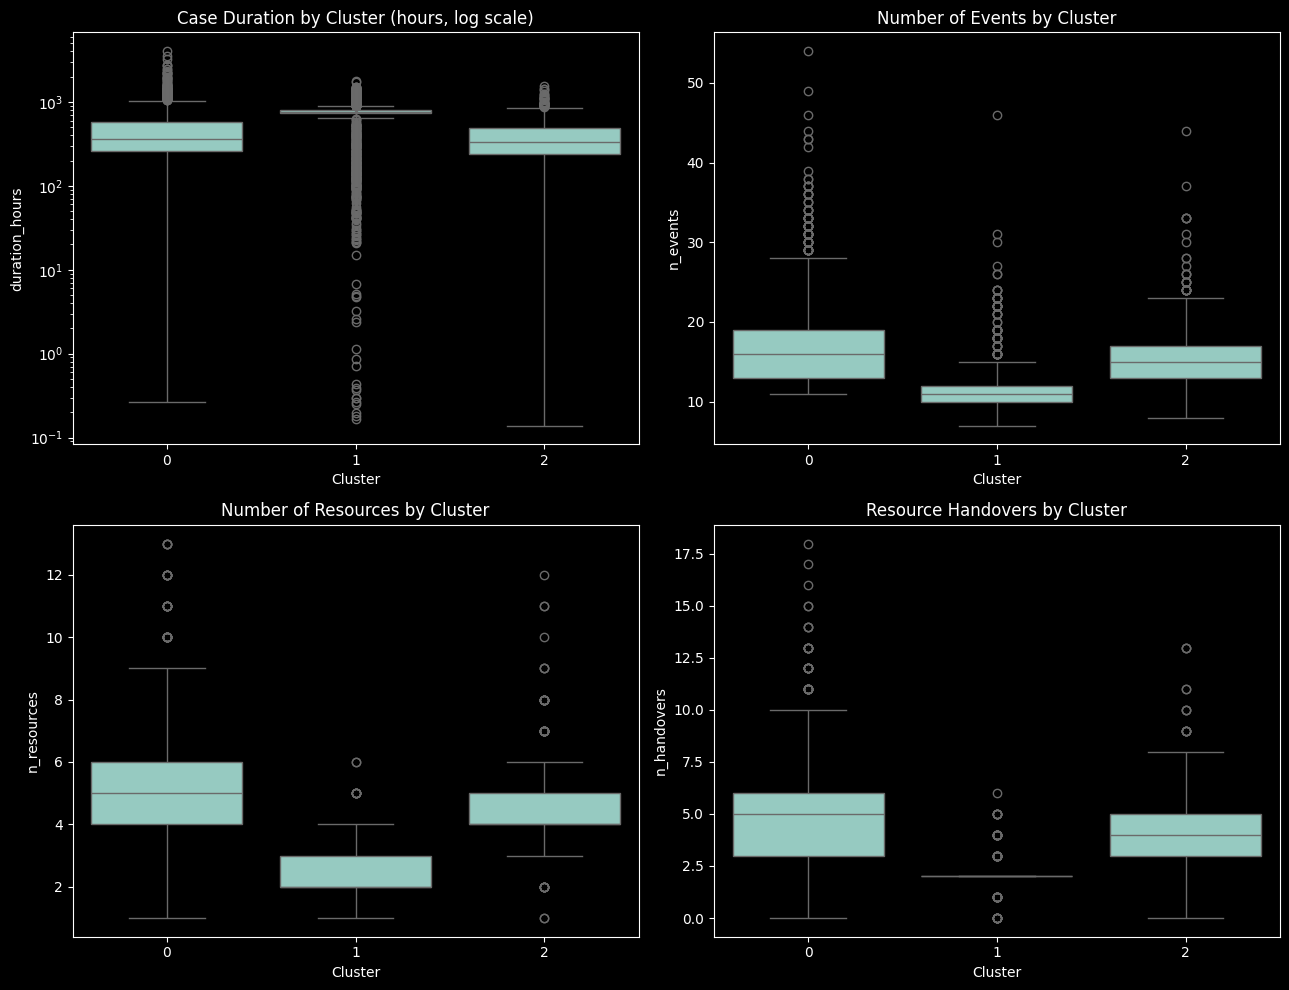

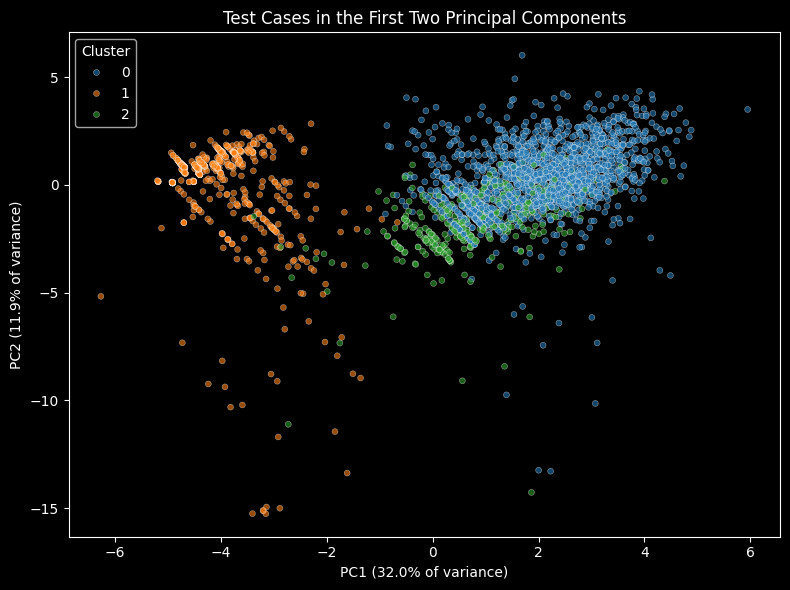

In [25]:
# Visualization of clusters differences

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

plots = [("duration_hours", "Case Duration by Cluster (hours, log scale)", True),
         ("n_events", "Number of Events by Cluster", False),
         ("n_resources", "Number of Resources by Cluster", False),
         ("n_handovers", "Resource Handovers by Cluster", False)]

for ax, (feature, title, use_log) in zip(axes.ravel(), plots):
    sns.boxplot(data=cluster_analysis, x="cluster", y=feature, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    if use_log:
        ax.set_yscale("log")

plt.tight_layout()
plt.savefig(f"{out}/cluster_differences.pdf", bbox_inches="tight")
plt.show()


# In order to visualize the test cases I chose PCA to reduce the dimentions

pca = PCA(n_components=2, random_state=random_state).fit(S["train"])
coords = pca.transform(S["test"])

sample = np.random.default_rng(random_state).choice(
    len(coords), size=min(3000, len(coords)), replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[sample, 0], y=coords[sample, 1],
                hue=test_clusters[sample], palette="tab10", alpha=0.6, s=18)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("Test Cases in the First Two Principal Components")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(f"{out}/cluster_pca.pdf", bbox_inches="tight")
plt.show()